# Task 1 — Pet breed classification

Train and compare custom, multi-task and pretrained models on Oxford-IIIT Pet.

In [1]:
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torch.utils.tensorboard import SummaryWriter
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from PIL import Image
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT = Path('data')
OUTPUT = Path('task1_results')
OUTPUT.mkdir(exist_ok=True)
print('Device:', DEVICE)

Device: cuda


C:\Users\Semoon\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data exploration and preprocessing

Split trainval by breed and keep the official test split for final evaluation.

100%|██████████| 792M/792M [00:21<00:00, 37.0MB/s] 
100%|██████████| 19.2M/19.2M [00:00<00:00, 30.4MB/s]


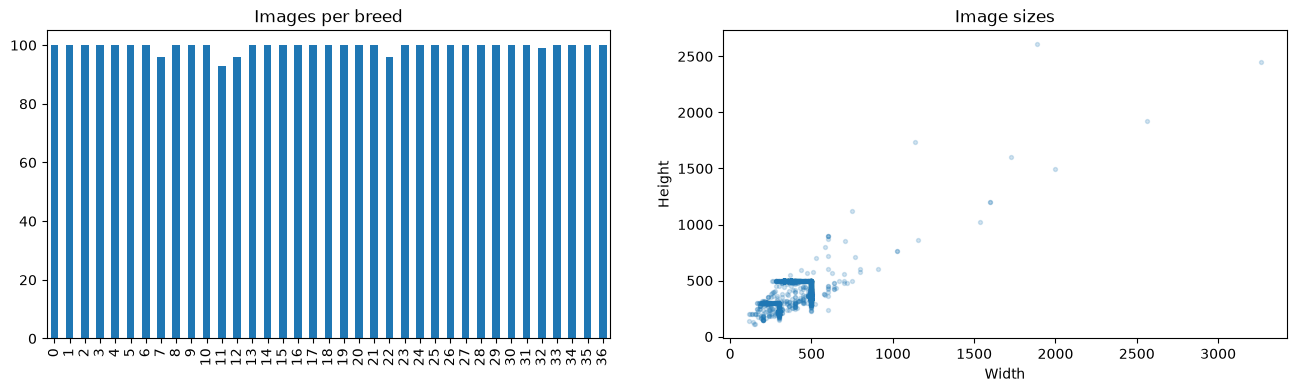

Train: 2944 Validation: 736
                     breed  train  validation
                Abyssinian     80          20
          American Bulldog     80          20
 American Pit Bull Terrier     80          20
              Basset Hound     80          20
                    Beagle     80          20
                    Bengal     80          20
                    Birman     80          20
                    Bombay     77          19
                     Boxer     80          20
         British Shorthair     80          20
                 Chihuahua     80          20
              Egyptian Mau     74          19
    English Cocker Spaniel     77          19
            English Setter     80          20
        German Shorthaired     80          20
            Great Pyrenees     80          20
                  Havanese     80          20
             Japanese Chin     80          20
                  Keeshond     80          20
                Leonberger     80          20
      

In [2]:
plain = datasets.OxfordIIITPet(ROOT, split='trainval', target_types=['category', 'binary-category'], download=True)
labels = np.array([target[0] for _, target in plain])
train_idx, val_idx = train_test_split(np.arange(len(labels)), test_size=0.2, stratify=labels, random_state=SEED)
np.savez(OUTPUT / 'split.npz', train=train_idx, validation=val_idx)
class_names = plain.classes
sizes = np.array([Image.open(path).size for path in plain._images])
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
pd.Series(labels).value_counts().sort_index().plot.bar(ax=axes[0], title='Images per breed')
axes[1].scatter(sizes[:, 0], sizes[:, 1], alpha=0.2, s=8)
axes[1].set(xlabel='Width', ylabel='Height', title='Image sizes')
plt.show()
print('Train:', len(train_idx), 'Validation:', len(val_idx))
print(pd.DataFrame({'breed': class_names, 'train': np.bincount(labels[train_idx], minlength=37), 'validation': np.bincount(labels[val_idx], minlength=37)}).to_string(index=False))

In [3]:
base_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])
aug_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(), transforms.RandomRotation(10), transforms.ToTensor()])
weights_resnet = models.ResNet50_Weights.DEFAULT
weights_eff = models.EfficientNet_B0_Weights.DEFAULT

def make_loaders(train_transform, eval_transform, batch_size=32):
    train_data = datasets.OxfordIIITPet(ROOT, split='trainval', target_types=['category', 'binary-category'], transform=train_transform)
    val_data = datasets.OxfordIIITPet(ROOT, split='trainval', target_types=['category', 'binary-category'], transform=eval_transform)
    split_path = OUTPUT / 'split.npz'
    if not split_path.exists():
        raise FileNotFoundError('Run the data exploration cell to create the train/validation split.')
    with np.load(split_path) as split:
        train_indices = split['train']
        validation_indices = split['validation']
    generator = torch.Generator().manual_seed(SEED)
    return (DataLoader(Subset(train_data, train_indices), batch_size=batch_size, shuffle=True, generator=generator, num_workers=0),
            DataLoader(Subset(val_data, validation_indices), batch_size=batch_size, shuffle=False, num_workers=0))

## Custom models

Add one technique at a time. The residual block is implemented from scratch.

In [4]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.layers = nn.Sequential(nn.Conv2d(channels, channels, 3, padding=1), nn.BatchNorm2d(channels), nn.ReLU(), nn.Conv2d(channels, channels, 3, padding=1), nn.BatchNorm2d(channels))
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(x + self.layers(x))

class PetCNN(nn.Module):
    def __init__(self, batch_norm=False, dropout=False, residual=False, multitask=False):
        super().__init__()
        layers = []
        for incoming, outgoing in [(3, 32), (32, 64), (64, 128), (128, 256)]:
            layers.append(nn.Conv2d(incoming, outgoing, 3, padding=1))
            if batch_norm:
                layers.append(nn.BatchNorm2d(outgoing))
            layers.extend([nn.ReLU(), nn.MaxPool2d(2)])
        if residual:
            layers.append(ResidualBlock(256))
        self.features = nn.Sequential(*layers)
        self.embedding = nn.Sequential(nn.Flatten(), nn.Linear(256 * 14 * 14, 512), nn.ReLU(), nn.Dropout(0.5) if dropout else nn.Identity())
        self.breed_head = nn.Linear(512, 37)
        self.species_head = nn.Linear(512, 2) if multitask else None

    def forward(self, x):
        x = self.embedding(self.features(x))
        breed = self.breed_head(x)
        return (breed, self.species_head(x)) if self.species_head is not None else breed

## Training and validation

Log loss, accuracy and macro F1 every epoch. Select checkpoints using validation macro F1.

In [5]:
def run_epoch(model, loader, criterion, optimizer=None, species_weight=0):
    training = optimizer is not None
    model.train(training)
    if training and getattr(model, 'frozen_backbone', False):
        model.backbone.eval()
    total_loss, targets, predictions = 0.0, [], []
    with torch.set_grad_enabled(training):
        for images, target in loader:
            images = images.to(DEVICE)
            breed = target[0].to(DEVICE)
            species = target[1].to(DEVICE)
            if training:
                optimizer.zero_grad()
            output = model(images)
            if isinstance(output, tuple):
                logits, species_logits = output
                loss = criterion(logits, breed) + species_weight * criterion(species_logits, species)
            else:
                logits = output
                loss = criterion(logits, breed)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            targets.extend(breed.cpu().numpy())
            predictions.extend(logits.argmax(1).cpu().numpy())
    return {'loss': total_loss / len(targets), 'accuracy': accuracy_score(targets, predictions), 'f1': f1_score(targets, predictions, labels=np.arange(37), average='macro', zero_division=0)}

def fit(model, train_loader, val_loader, optimizer, name, epochs=15, species_weight=0):
    model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    writer = SummaryWriter(str(OUTPUT / 'runs' / name))
    best_f1 = -1
    history = []
    for epoch in range(epochs):
        train_metrics = run_epoch(model, train_loader, criterion, optimizer, species_weight)
        val_metrics = run_epoch(model, val_loader, criterion, species_weight=species_weight)
        for key in train_metrics:
            writer.add_scalars(key, {'train': train_metrics[key], 'validation': val_metrics[key]}, epoch + 1)
        history.append({'epoch': epoch + 1, **{'train_' + k: v for k, v in train_metrics.items()}, **{'val_' + k: v for k, v in val_metrics.items()}})
        print(name, epoch + 1, 'train', train_metrics, 'validation', val_metrics)
        if val_metrics['f1'] > best_f1:
            best_f1 = val_metrics['f1']
            torch.save(model.state_dict(), OUTPUT / (name + '.pt'))
    writer.close()
    model.load_state_dict(torch.load(OUTPUT / (name + '.pt'), map_location=DEVICE, weights_only=True))
    return model, pd.DataFrame(history)

In [6]:
experiments = [
    ('baseline', False, False, False, False),
    ('batch_norm', True, False, False, False),
    ('dropout', True, True, False, False),
    ('augmentation', True, True, False, True),
    ('residual', True, True, True, True),
]
results = []
for name, bn, drop, residual, augment in experiments:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    train_loader, val_loader = make_loaders(aug_transform if augment else base_transform, base_transform)
    model = PetCNN(bn, drop, residual).to(DEVICE)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.001)
    model, history = fit(model, train_loader, val_loader, optimizer, name)
    best = history.loc[history.val_f1.idxmax()]
    results.append({'model': name, 'accuracy': best.val_accuracy, 'macro_f1': best.val_f1, 'epoch': int(best.epoch)})
    history.to_csv(OUTPUT / (name + '_history.csv'), index=False)
    del model, optimizer
ablation = pd.DataFrame(results)
ablation['delta_accuracy'] = ablation.accuracy.diff()
ablation['delta_f1'] = ablation.macro_f1.diff()
display(ablation)
best_name = ablation.loc[ablation.macro_f1.idxmax(), 'model']
best_config = next(item for item in experiments if item[0] == best_name)
print('Selected custom model:', best_name)

baseline 1 train {'loss': 3.6113077790840813, 'accuracy': 0.028192934782608696, 'f1': 0.0024919236815147596} validation {'loss': 3.6112385729084844, 'accuracy': 0.028532608695652172, 'f1': 0.0021602060037200737}
baseline 2 train {'loss': 3.611255267392034, 'accuracy': 0.028872282608695652, 'f1': 0.002642390704291957} validation {'loss': 3.611201980839605, 'accuracy': 0.028532608695652172, 'f1': 0.002098439903317952}
baseline 3 train {'loss': 3.611205305742181, 'accuracy': 0.030570652173913044, 'f1': 0.0030002063900368982} validation {'loss': 3.6111700534820557, 'accuracy': 0.028532608695652172, 'f1': 0.0020887210661753534}
baseline 4 train {'loss': 3.61115955269855, 'accuracy': 0.028532608695652172, 'f1': 0.00301783149124487} validation {'loss': 3.611139909080837, 'accuracy': 0.028532608695652172, 'f1': 0.0020930792543695773}
baseline 5 train {'loss': 3.611119703106258, 'accuracy': 0.03158967391304348, 'f1': 0.0030949619370672006} validation {'loss': 3.6111113817795464, 'accuracy': 0.0

,model,accuracy,macro_f1,epoch,delta_accuracy,delta_f1
0,baseline,0.028533,0.002438,14,NaN,NaN
1,batch_norm,0.235054,0.216102,14,0.206522,0.213664
2,dropout,0.221467,0.206990,15,-0.013587,-0.009111
3,augmentation,0.194293,0.185342,10,-0.027174,-0.021648
4,residual,0.229620,0.214576,15,0.035326,0.029234


Selected custom model: batch_norm


## Multi-task learning

Compare two weights for the species loss with the single-task model.

In [7]:
multitask_results = []
for weight in [0.25, 1.0]:
    _, bn, drop, residual, augment = best_config
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    model = PetCNN(bn, drop, residual, multitask=True).to(DEVICE)
    train_loader, val_loader = make_loaders(aug_transform if augment else base_transform, base_transform)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.001)
    name = 'multitask_' + str(weight)
    model, history = fit(model, train_loader, val_loader, optimizer, name, species_weight=weight)
    best = history.loc[history.val_f1.idxmax()]
    multitask_results.append({'model': name, 'weight': weight, 'accuracy': best.val_accuracy, 'macro_f1': best.val_f1})
    del model, optimizer
multitask_table = pd.DataFrame(multitask_results)
display(multitask_table)
print('Single-task:', ablation.loc[ablation.model == best_name, ['accuracy', 'macro_f1']])
best_multi = multitask_table.loc[multitask_table.macro_f1.idxmax(), 'model']

multitask_0.25 1 train {'loss': 3.722672967807106, 'accuracy': 0.051970108695652176, 'f1': 0.04595695762672706} validation {'loss': 3.6380740974260415, 'accuracy': 0.08423913043478261, 'f1': 0.051621078893032496}
multitask_0.25 2 train {'loss': 3.466659444829692, 'accuracy': 0.14605978260869565, 'f1': 0.13565628240535266} validation {'loss': 3.499133773471998, 'accuracy': 0.11684782608695653, 'f1': 0.09331887628300567}
multitask_0.25 3 train {'loss': 3.2119597844455554, 'accuracy': 0.2235054347826087, 'f1': 0.20691719720991633} validation {'loss': 3.4040482769841733, 'accuracy': 0.12771739130434784, 'f1': 0.1087963552998601}
multitask_0.25 4 train {'loss': 2.9945614726647087, 'accuracy': 0.27717391304347827, 'f1': 0.26649326692334635} validation {'loss': 3.3121468502542246, 'accuracy': 0.15489130434782608, 'f1': 0.13226521412611003}
multitask_0.25 5 train {'loss': 2.7896159550418025, 'accuracy': 0.3376358695652174, 'f1': 0.32591944385691424} validation {'loss': 3.227498448413351, 'accu

,model,weight,accuracy,macro_f1
0,multitask_0.25,0.25,0.230978,0.219928
1,multitask_1.0,1.00,0.241848,0.228652


Single-task:    accuracy  macro_f1
1  0.235054  0.216102


## Transfer learning

Compare two ImageNet backbones and two strategies for ResNet-50.

In [8]:
class TransferModel(nn.Module):
    def __init__(self, architecture, frozen=False):
        super().__init__()
        if architecture == 'resnet50':
            self.backbone = models.resnet50(weights=weights_resnet)
            size = self.backbone.fc.in_features
            self.backbone.fc = nn.Identity()
        else:
            self.backbone = models.efficientnet_b0(weights=weights_eff)
            size = self.backbone.classifier[1].in_features
            self.backbone.classifier = nn.Identity()
        self.head = nn.Linear(size, 37)
        self.frozen_backbone = frozen
        if frozen:
            for parameter in self.backbone.parameters():
                parameter.requires_grad = False

    def forward(self, x):
        return self.head(self.backbone(x))

transfer_specs = [('resnet_frozen', 'resnet50', True), ('resnet_finetuned', 'resnet50', False), ('efficientnet_finetuned', 'efficientnet', False)]
transfer_results = []
for name, architecture, frozen in transfer_specs:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    model = TransferModel(architecture, frozen).to(DEVICE)
    transform = weights_resnet.transforms() if architecture == 'resnet50' else weights_eff.transforms()
    train_loader, val_loader = make_loaders(transform, transform)
    optimizer = torch.optim.Adam([{'params': model.backbone.parameters(), 'lr': 1e-5}, {'params': model.head.parameters(), 'lr': 1e-4}])
    model, history = fit(model, train_loader, val_loader, optimizer, name)
    best = history.loc[history.val_f1.idxmax()]
    transfer_results.append({'model': name, 'accuracy': best.val_accuracy, 'macro_f1': best.val_f1})
    del model, optimizer
transfer_table = pd.DataFrame(transfer_results)
display(transfer_table)
best_transfer = transfer_table.loc[transfer_table.macro_f1.idxmax(), 'model']

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\Semoon/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 72.0MB/s]


resnet_frozen 1 train {'loss': 3.4066424784453018, 'accuracy': 0.23199728260869565, 'f1': 0.2181970969101385} validation {'loss': 3.1916474674059, 'accuracy': 0.5040760869565217, 'f1': 0.4797909833561443}
resnet_frozen 2 train {'loss': 3.0023925071177273, 'accuracy': 0.6691576086956522, 'f1': 0.6589649145764104} validation {'loss': 2.8334096203679624, 'accuracy': 0.7432065217391305, 'f1': 0.7322074488040835}
resnet_frozen 3 train {'loss': 2.650316730789516, 'accuracy': 0.8196331521739131, 'f1': 0.8158001693376097} validation {'loss': 2.5151473128277324, 'accuracy': 0.8233695652173914, 'f1': 0.8204920865544931}
resnet_frozen 4 train {'loss': 2.3359342165615247, 'accuracy': 0.8824728260869565, 'f1': 0.8815526867121677} validation {'loss': 2.231797975042592, 'accuracy': 0.8709239130434783, 'f1': 0.8705773480068796}
resnet_frozen 5 train {'loss': 2.056756159533625, 'accuracy': 0.9167798913043478, 'f1': 0.915932170778514} validation {'loss': 1.9811570955359417, 'accuracy': 0.889945652173913

100%|██████████| 20.5M/20.5M [00:00<00:00, 31.2MB/s]


efficientnet_finetuned 1 train {'loss': 3.377411943414937, 'accuracy': 0.21773097826086957, 'f1': 0.21323988806869024} validation {'loss': 3.0401633096777876, 'accuracy': 0.5448369565217391, 'f1': 0.542964047415612}
efficientnet_finetuned 2 train {'loss': 2.755743462106456, 'accuracy': 0.6345108695652174, 'f1': 0.6320967718126711} validation {'loss': 2.333214521408081, 'accuracy': 0.7785326086956522, 'f1': 0.7746005100927231}
efficientnet_finetuned 3 train {'loss': 2.0781652707120646, 'accuracy': 0.790421195652174, 'f1': 0.7894922478784832} validation {'loss': 1.6523947974909907, 'accuracy': 0.8410326086956522, 'f1': 0.8387877815518118}
efficientnet_finetuned 4 train {'loss': 1.4979194584100142, 'accuracy': 0.8301630434782609, 'f1': 0.8274803898222268} validation {'loss': 1.1523687321206797, 'accuracy': 0.8559782608695652, 'f1': 0.8530245617998188}
efficientnet_finetuned 5 train {'loss': 1.0938271828319714, 'accuracy': 0.8549592391304348, 'f1': 0.853356121861663} validation {'loss': 0.

,model,accuracy,macro_f1
0,resnet_frozen,0.933424,0.933869
1,resnet_finetuned,0.942935,0.943488
2,efficientnet_finetuned,0.917120,0.917276


## Final test evaluation

Evaluate the four selected models after validation choices are fixed.

In [9]:
def load_selected(name):
    if name == 'baseline':
        model, transform = PetCNN(), base_transform
    elif name == best_name:
        _, bn, drop, residual, _ = best_config
        model, transform = PetCNN(bn, drop, residual), base_transform
    elif name == best_multi:
        _, bn, drop, residual, _ = best_config
        model, transform = PetCNN(bn, drop, residual, multitask=True), base_transform
    else:
        _, architecture, frozen = next(s for s in transfer_specs if s[0] == name)
        model = TransferModel(architecture, frozen)
        transform = weights_resnet.transforms() if architecture == 'resnet50' else weights_eff.transforms()
    model.load_state_dict(torch.load(OUTPUT / (name + '.pt'), map_location=DEVICE, weights_only=True))
    return model.to(DEVICE).eval(), transform

def predict_test(model, transform):
    data = datasets.OxfordIIITPet(ROOT, split='test', target_types=['category', 'binary-category'], transform=transform, download=True)
    loader = DataLoader(data, batch_size=32, shuffle=False, num_workers=0)
    targets, scores = [], []
    with torch.no_grad():
        for images, target in loader:
            output = model(images.to(DEVICE))
            logits = output[0] if isinstance(output, tuple) else output
            scores.append(logits.cpu())
            targets.extend(target[0].numpy())
    return np.array(targets), torch.cat(scores).numpy()

selected = [('baseline', 'baseline'), ('custom', best_name), ('multitask', best_multi), ('transfer', best_transfer)]
test_results, test_outputs = [], {}
for label, name in selected:
    model, transform = load_selected(name)
    targets, scores = predict_test(model, transform)
    preds = scores.argmax(axis=1)
    top5 = np.argsort(scores, axis=1)[:, -5:]
    test_results.append({'model': label, 'checkpoint': name, 'accuracy': accuracy_score(targets, preds), 'top5': np.mean([y in row for y, row in zip(targets, top5)]), 'macro_f1': f1_score(targets, preds, labels=np.arange(37), average='macro', zero_division=0)})
    test_outputs[label] = (targets, scores)
    del model
display(pd.DataFrame(test_results))

,model,checkpoint,accuracy,top5,macro_f1
0,baseline,baseline,0.027528,0.135732,0.001863
1,custom,batch_norm,0.192968,0.530390,0.181662
2,multitask,multitask_1.0,0.199782,0.542382,0.188648
3,transfer,resnet_finetuned,0.923685,0.995367,0.922434


## Error analysis and Grad-CAM

The best model is selected using validation macro F1. Grad-CAM uses the predicted class.

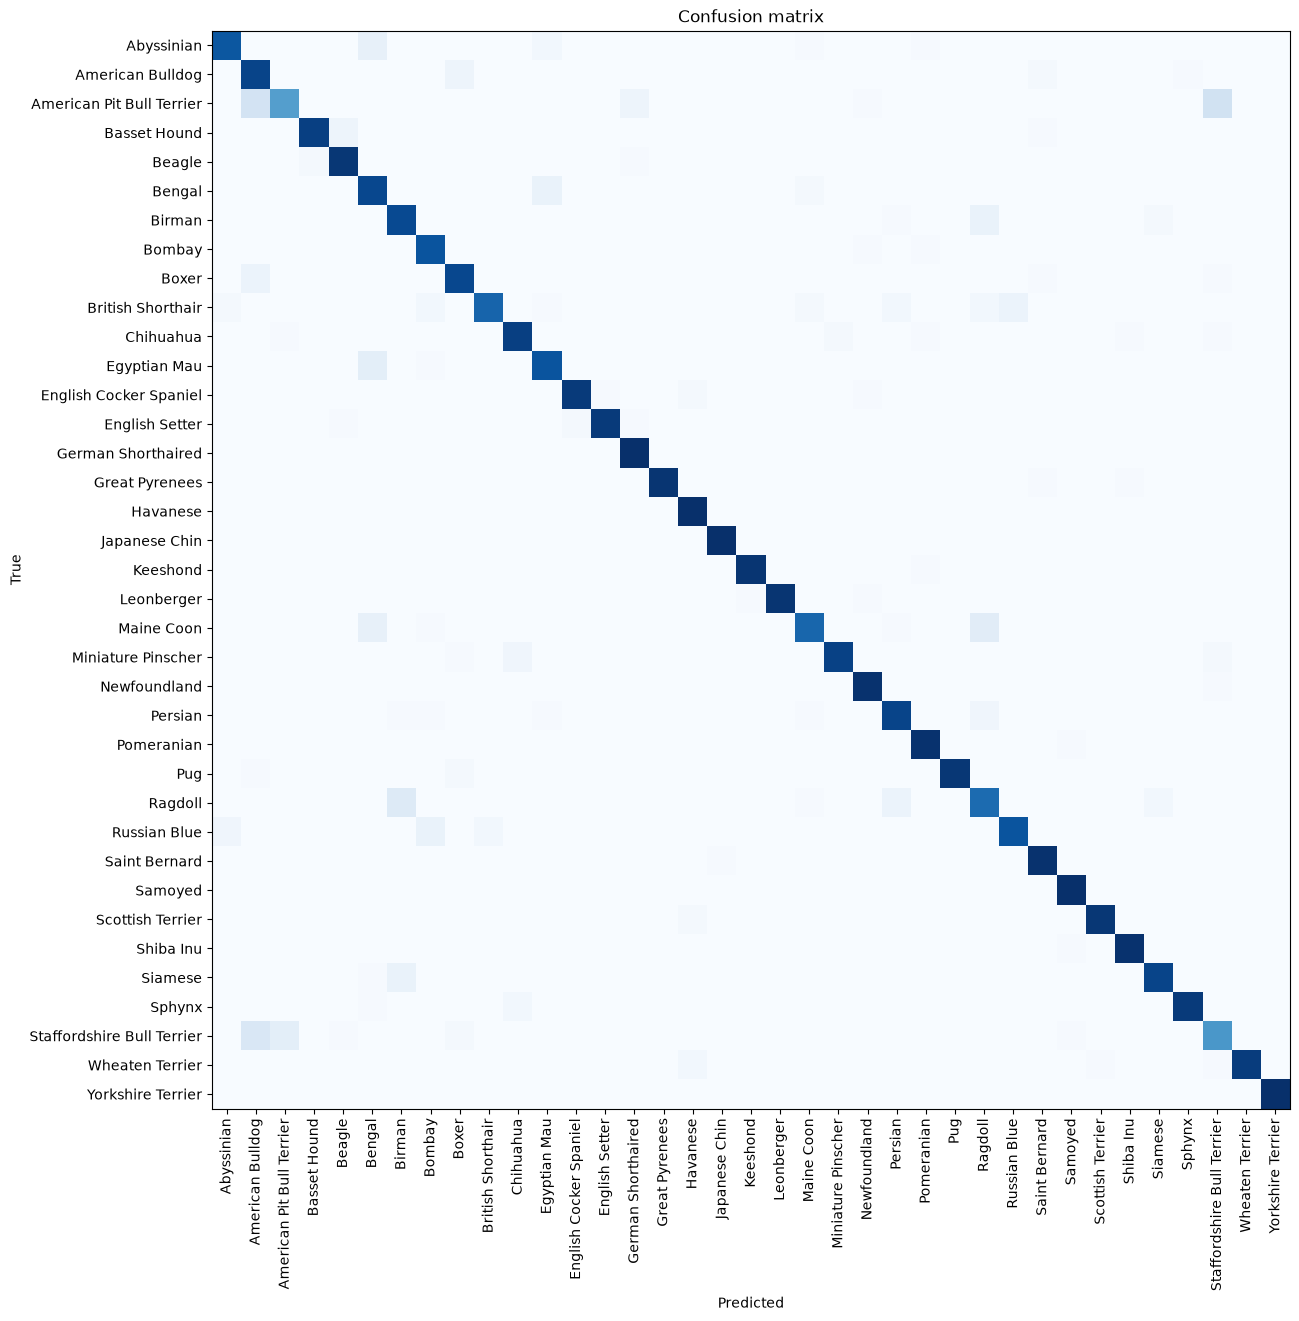

,count,breed 1,breed 2
0,29,American Pit Bull Terrier,Staffordshire Bull Terrier
1,20,Birman,Ragdoll
2,18,American Bulldog,American Pit Bull Terrier
3,17,Bengal,Egyptian Mau
4,15,American Bulldog,Staffordshire Bull Terrier


In [10]:
candidates = [('baseline', ablation.iloc[0].macro_f1), ('custom', ablation.macro_f1.max()), ('multitask', multitask_table.macro_f1.max()), ('transfer', transfer_table.macro_f1.max())]
best_label = max(candidates, key=lambda item: item[1])[0]
best_checkpoint = dict(selected)[best_label]
targets, scores = test_outputs[best_label]
preds = scores.argmax(axis=1)
cm = confusion_matrix(targets, preds, labels=np.arange(37))
fig, ax = plt.subplots(figsize=(16, 14))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(37), class_names, rotation=90)
ax.set_yticks(range(37), class_names)
ax.set(xlabel='Predicted', ylabel='True', title='Confusion matrix')
plt.show()
pairs = [(cm[i, j] + cm[j, i], class_names[i], class_names[j]) for i in range(37) for j in range(i + 1, 37)]
display(pd.DataFrame(sorted(pairs, reverse=True)[:5], columns=['count', 'breed 1', 'breed 2']))

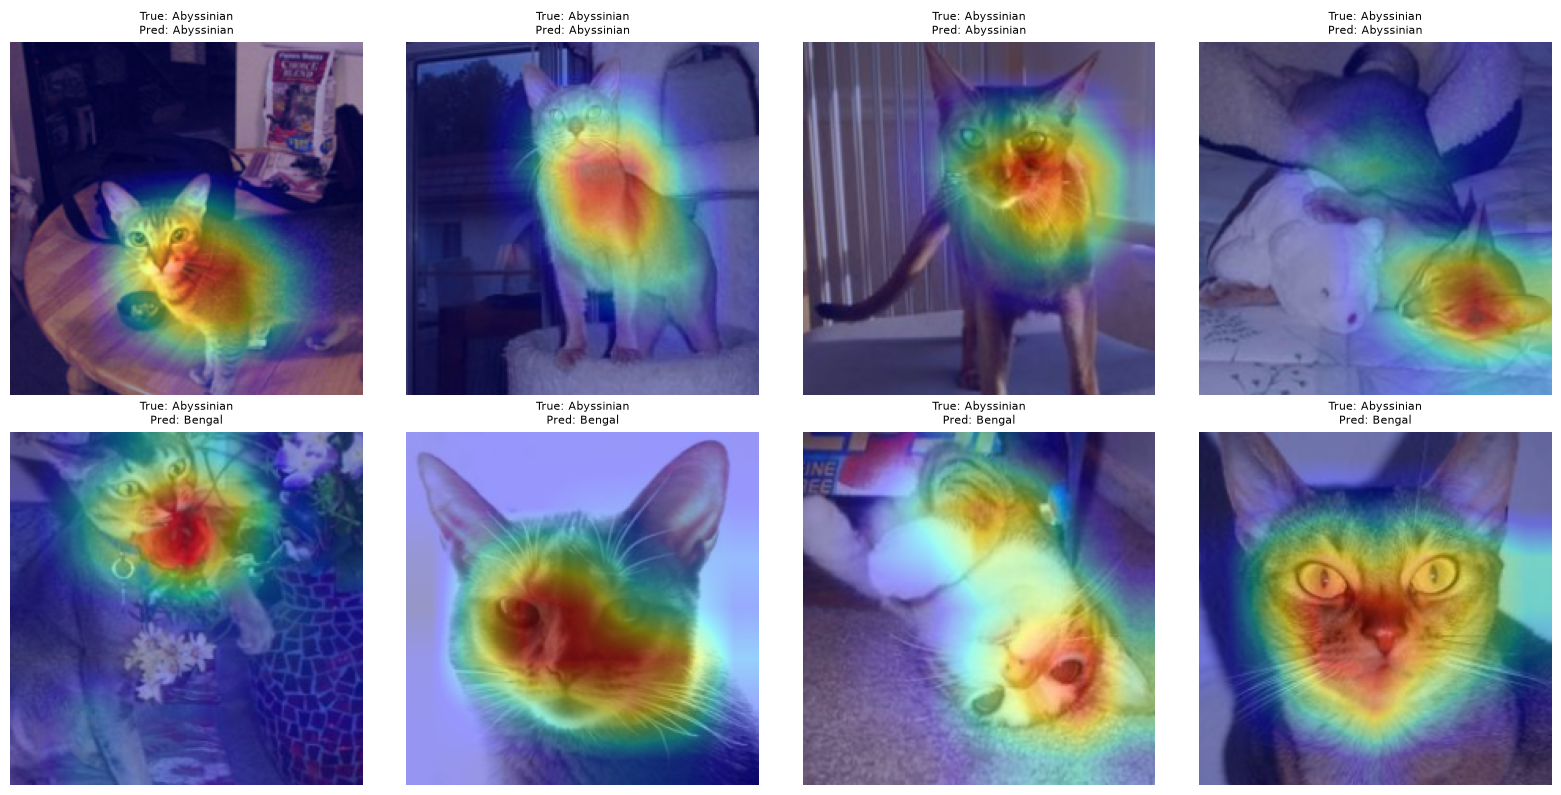

In [11]:
model, transform = load_selected(best_checkpoint)
if isinstance(model, PetCNN):
    conv_layer = [layer for layer in model.features.modules() if isinstance(layer, nn.Conv2d)][-1]
else:
    conv_layer = [layer for layer in model.backbone.modules() if isinstance(layer, nn.Conv2d)][-1]
for layer in model.modules():
    if isinstance(layer, nn.ReLU):
        layer.inplace = False
activations, gradients = [], []
def save_activation(module, inputs, output):
    activations.append(output.detach())
def save_gradient(module, grad_input, grad_output):
    gradients.append(grad_output[0].detach())
forward_hook = conv_layer.register_forward_hook(save_activation)
backward_hook = conv_layer.register_full_backward_hook(save_gradient)
raw_test = datasets.OxfordIIITPet(ROOT, split='test', target_types=['category', 'binary-category'])
indices = np.concatenate([np.flatnonzero(preds == targets)[:4], np.flatnonzero(preds != targets)[:4]])
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, idx in zip(axes.flat, indices):
    image, _ = raw_test[int(idx)]
    tensor = transform(image).unsqueeze(0).to(DEVICE)
    activations.clear()
    gradients.clear()
    model.zero_grad()
    output = model(tensor)
    logits = output[0] if isinstance(output, tuple) else output
    logits[0, int(preds[idx])].backward()
    weights = gradients[-1].mean(dim=(2, 3), keepdim=True)
    heatmap = torch.relu((weights * activations[-1]).sum(dim=1, keepdim=True))
    heatmap = nn.functional.interpolate(heatmap, size=tensor.shape[-2:], mode='bilinear', align_corners=False)[0, 0].cpu().numpy()
    heatmap /= max(float(heatmap.max()), 1e-8)
    # Display the same spatially transformed image used by the model.
    shown = tensor[0].detach().cpu()
    if best_label == 'transfer':
        shown = shown * torch.tensor([0.229, 0.224, 0.225])[:, None, None] + torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    ax.imshow(shown.permute(1, 2, 0).clamp(0, 1))
    ax.imshow(heatmap, cmap='jet', alpha=0.4)
    ax.set_title(f'True: {class_names[targets[idx]]}\nPred: {class_names[preds[idx]]}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()
forward_hook.remove()
backward_hook.remove()

## Conclusion

Compare the validation ablation, multi-task and transfer results. Interpret the confusion pairs and Grad-CAM images after running the experiments, including whether attention falls on the animal or background.